# 📞 Modul 5 — Praktikum Distribusi Diskret

### Studi Kasus: Telco Customer Churn — Bernoulli, Binomial, Poisson & A/B Testing

**Mata Kuliah:** Statistika & Probabilitas (TIF1501)  
**Program Studi:** Teknik Informatika (55201) · FTI · Uniska MAB Banjarmasin  
**Semester:** 5 · 3 SKS

---

## 🎯 Tujuan Pembelajaran

Setelah menyelesaikan notebook ini, Anda akan mampu:

1. **Menerapkan** distribusi Bernoulli pada eksperimen tunggal success/failure.
2. **Memodelkan** jumlah success dalam n trial dengan distribusi Binomial.
3. **Memodelkan** kejadian langka per waktu/area dengan distribusi Poisson.
4. **Mengimplementasikan** A/B Testing dengan Binomial di customer churn nyata.

---

## 📋 Alur Notebook

| Bagian | Isi | Waktu |
|--------|-----|-------|
| **A** | Setup & Load Telco Churn Dataset | 10 menit |
| **B** | EDA Churn Rate | 10 menit |
| **C** | Distribusi Bernoulli: Satu Customer | 10 menit |
| **D** | Distribusi Binomial: Grup Customer | 15 menit |
| **E** | Distribusi Poisson: Monthly Churn Rate | 10 menit |
| **F** | A/B Test: Contract Type (LATIHAN UTAMA) | 15 menit |
| **G** | A/B Test: PaymentMethod Multi-group | 10 menit |
| **H** | Refleksi & Submit ke GitHub | 10 menit |

**Total: ± 90 menit**

---

## 💡 Kenapa Telco Churn?

Dataset **Telco Customer Churn** adalah salah satu dataset paling populer di Kaggle untuk analisis bisnis:

- ✅ **7.043 pelanggan nyata** telekomunikasi dengan 21 kolom
- ✅ Target biner (Churn: Yes/No) — perfect untuk **Bernoulli**
- ✅ Beberapa segment (Contract, PaymentMethod) — perfect untuk **A/B Testing**
- ✅ Churn rate real-world ~26.5% — menarik untuk eksplorasi statistik
- ✅ Industri telkom (Telkomsel, Indosat, Smartfren) di Indonesia memiliki masalah serupa


---

# 🔧 A. Setup & Load Telco Churn Dataset

## A.1 Import Library


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# scipy untuk distribusi diskret
from scipy import stats
from scipy.stats import bernoulli, binom, poisson
from scipy.stats import norm   # untuk z-test
from statsmodels.stats.proportion import proportions_ztest   # A/B test ready-made

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("Library siap untuk Modul 5!")
print(f"NumPy  : {np.__version__}")
print(f"Pandas : {pd.__version__}")


Library siap untuk Modul 5!
NumPy  : 2.1.3
Pandas : 2.2.3


## A.2 Load Dataset dari Kaggle Mirror


In [2]:
# URL dataset Telco Customer Churn
url = "https://raw.githubusercontent.com/treselle-systems/customer_churn_analysis/master/WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(url)

print(f"Dataset berhasil dimuat!")
print(f"Shape: {df.shape[0]:,} baris × {df.shape[1]} kolom")
print(f"\nKolom:")
for i, col in enumerate(df.columns, 1):
    print(f"  {i:2d}. {col}")

df.head()


Dataset berhasil dimuat!
Shape: 7,043 baris × 21 kolom

Kolom:
   1. customerID
   2. gender
   3. SeniorCitizen
   4. Partner
   5. Dependents
   6. tenure
   7. PhoneService
   8. MultipleLines
   9. InternetService
  10. OnlineSecurity
  11. OnlineBackup
  12. DeviceProtection
  13. TechSupport
  14. StreamingTV
  15. StreamingMovies
  16. Contract
  17. PaperlessBilling
  18. PaymentMethod
  19. MonthlyCharges
  20. TotalCharges
  21. Churn


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## A.3 Encode Churn ke Binary (0/1)


In [3]:
# Encode Churn: Yes → 1, No → 0
df['Churn_binary'] = (df['Churn'] == 'Yes').astype(int)

# Cek distribusi
print("Distribusi Churn:")
print(df['Churn'].value_counts())
print(f"\nBinary encoding:")
print(df['Churn_binary'].value_counts())

# Hitung churn rate overall
overall_churn_rate = df['Churn_binary'].mean()
print(f"\n🎯 Overall Churn Rate: {overall_churn_rate:.4f}  ({overall_churn_rate*100:.2f}%)")


Distribusi Churn:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Binary encoding:
Churn_binary
0    5174
1    1869
Name: count, dtype: int64

🎯 Overall Churn Rate: 0.2654  (26.54%)


---

# 🔍 B. EDA: Churn Rate per Segmen

## B.1 Visualisasi Overall Churn


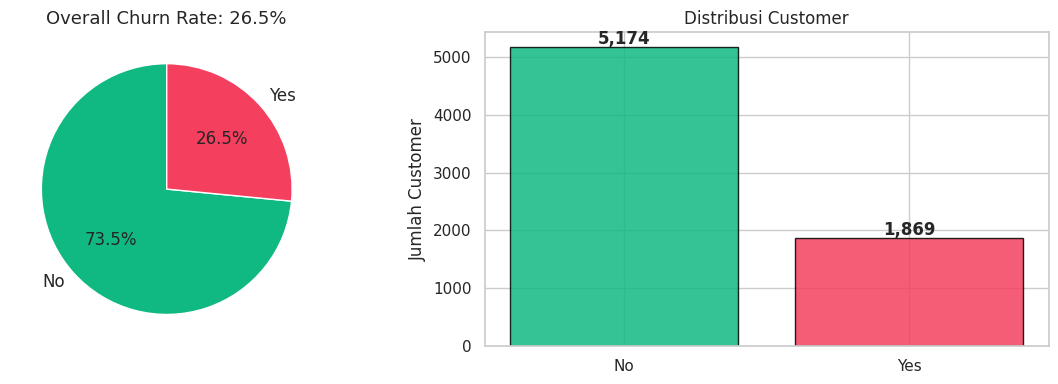

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Pie chart
churn_counts = df['Churn'].value_counts()
axes[0].pie(churn_counts.values, labels=churn_counts.index,
            colors=['#10B981', '#F43F5E'], autopct='%1.1f%%',
            startangle=90, textprops={'fontsize': 12})
axes[0].set_title(f'Overall Churn Rate: {overall_churn_rate*100:.1f}%', fontsize=13)

# Bar chart
axes[1].bar(churn_counts.index, churn_counts.values,
            color=['#10B981', '#F43F5E'], edgecolor='black', alpha=0.85)
axes[1].set_ylabel('Jumlah Customer')
axes[1].set_title('Distribusi Customer')
for i, v in enumerate(churn_counts.values):
    axes[1].text(i, v + 50, f'{v:,}', ha='center', fontweight='bold', fontsize=12)

plt.tight_layout()
plt.show()


## B.2 Churn Rate per Contract Type


Churn rate per Contract type:
                n_customers  n_churned  churn_rate
Contract                                          
Month-to-month         3875       1655      0.4271
One year               1473        166      0.1127
Two year               1695         48      0.0283


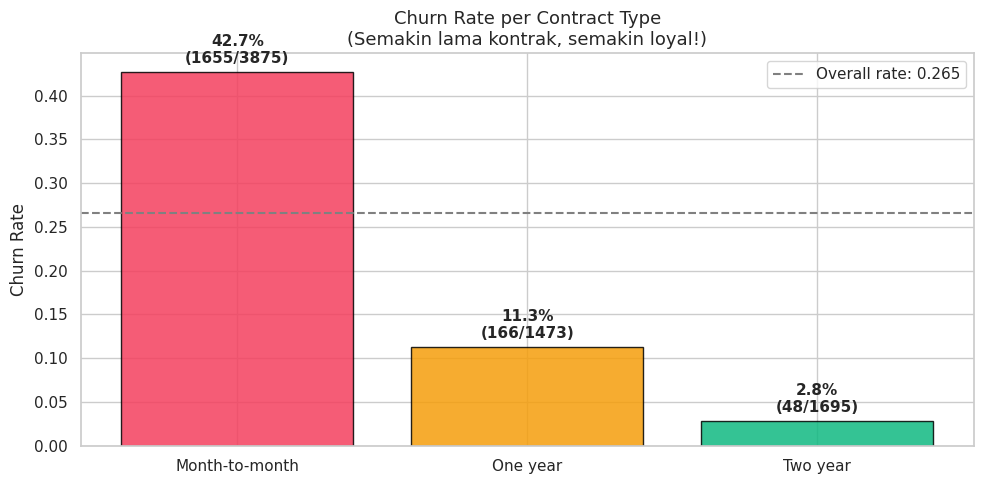


💡 Insight: Month-to-month = 15× lebih churn-prone daripada Two year!


In [5]:
# Hitung churn rate per Contract
contract_summary = df.groupby('Contract').agg(
    n_customers=('Churn_binary', 'count'),
    n_churned=('Churn_binary', 'sum'),
    churn_rate=('Churn_binary', 'mean')
).round(4)

print("Churn rate per Contract type:")
print(contract_summary)

# Visualisasi
fig, ax = plt.subplots(figsize=(10, 5))
colors = ['#F43F5E', '#F59E0B', '#10B981']
bars = ax.bar(contract_summary.index, contract_summary['churn_rate'].values,
              color=colors, edgecolor='black', alpha=0.85)
ax.set_ylabel('Churn Rate', fontsize=12)
ax.set_title('Churn Rate per Contract Type\n(Semakin lama kontrak, semakin loyal!)', fontsize=13)
ax.axhline(overall_churn_rate, color='gray', linestyle='--',
           label=f'Overall rate: {overall_churn_rate:.3f}')

for bar, rate, n_churn, n_total in zip(bars, contract_summary['churn_rate'],
                                        contract_summary['n_churned'],
                                        contract_summary['n_customers']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{rate*100:.1f}%\n({n_churn}/{n_total})',
            ha='center', fontweight='bold', fontsize=11)

ax.legend()
plt.tight_layout()
plt.show()

print("\n💡 Insight: Month-to-month = 15× lebih churn-prone daripada Two year!")


---

# 🎲 C. Distribusi Bernoulli: Setiap Customer Independen

**Tujuan Pembelajaran 1** — Model satu customer dengan Bernoulli.

## C.1 Setup Model

Setiap customer bisa dimodelkan sebagai:
$$X_i \sim \text{Bernoulli}(p)$$

dimana p = probabilitas churn = overall rate.


In [6]:
# Parameter Bernoulli dari data empiris
p = overall_churn_rate
print(f"Parameter Bernoulli: p = {p:.4f}")
print(f"P(X = 1) = P(churn)   = {p:.4f}")
print(f"P(X = 0) = P(stay)    = {1-p:.4f}")

# E(X) dan Var(X) teoritis
E_X_theory = p
Var_X_theory = p * (1 - p)
SD_X_theory = np.sqrt(Var_X_theory)

print(f"\nSifat teoritis Bernoulli({p:.4f}):")
print(f"  E(X)   = p         = {E_X_theory:.4f}")
print(f"  Var(X) = p(1-p)    = {Var_X_theory:.4f}")
print(f"  σ      = √Var(X)   = {SD_X_theory:.4f}")

# Verifikasi dengan empiris
E_X_empirical = df['Churn_binary'].mean()
Var_X_empirical = df['Churn_binary'].var(ddof=0)  # population variance

print(f"\nVerifikasi dari data empiris (n={len(df)}):")
print(f"  E(X) empiris   = {E_X_empirical:.4f}  (teori: {E_X_theory:.4f})")
print(f"  Var(X) empiris = {Var_X_empirical:.4f}  (teori: {Var_X_theory:.4f})")
print(f"\n✅ Teori dan empiris cocok!")


Parameter Bernoulli: p = 0.2654
P(X = 1) = P(churn)   = 0.2654
P(X = 0) = P(stay)    = 0.7346

Sifat teoritis Bernoulli(0.2654):
  E(X)   = p         = 0.2654
  Var(X) = p(1-p)    = 0.1949
  σ      = √Var(X)   = 0.4415

Verifikasi dari data empiris (n=7043):
  E(X) empiris   = 0.2654  (teori: 0.2654)
  Var(X) empiris = 0.1949  (teori: 0.1949)

✅ Teori dan empiris cocok!


## C.2 Visualisasi PMF Bernoulli


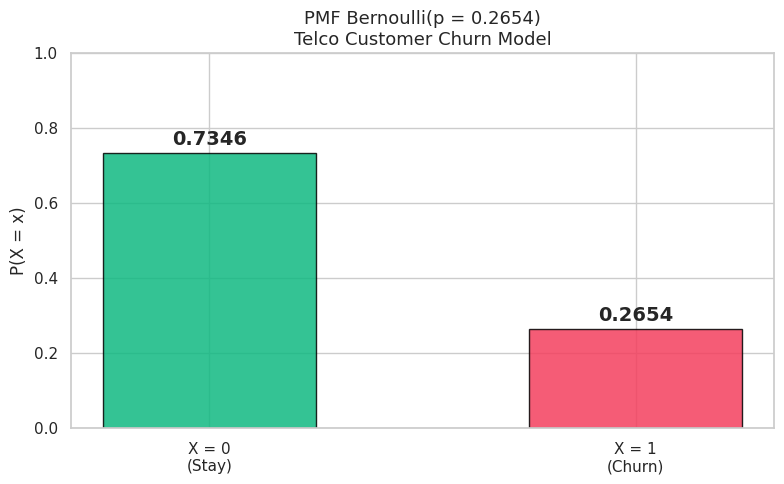

P(X=1) scipy = 0.2654
P(X=0) scipy = 0.7346


In [7]:
# Plot PMF Bernoulli
x_values = [0, 1]
pmf_values = [1-p, p]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(x_values, pmf_values, color=['#10B981', '#F43F5E'],
              edgecolor='black', alpha=0.85, width=0.5)
ax.set_xticks([0, 1])
ax.set_xticklabels(['X = 0\n(Stay)', 'X = 1\n(Churn)'])
ax.set_ylabel('P(X = x)', fontsize=12)
ax.set_title(f'PMF Bernoulli(p = {p:.4f})\nTelco Customer Churn Model', fontsize=13)

for bar, prob in zip(bars, pmf_values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
            f'{prob:.4f}', ha='center', fontweight='bold', fontsize=14)

ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

# Verifikasi dengan scipy
print(f"P(X=1) scipy = {bernoulli.pmf(1, p):.4f}")
print(f"P(X=0) scipy = {bernoulli.pmf(0, p):.4f}")


---

# 📊 D. Distribusi Binomial: Grup n Customer

**Tujuan Pembelajaran 2** — Model jumlah churn dari n customer dengan Binomial.

## D.1 Setup Skenario

Misal kita ambil random sample n = 100 customer. Pertanyaan: berapa banyak yang akan churn?

$$X \sim \text{Binomial}(n = 100, p = 0.265)$$


In [8]:
n = 100
p = overall_churn_rate

# Parameter Binomial
E_X = n * p
Var_X = n * p * (1 - p)
SD_X = np.sqrt(Var_X)

print(f"Model: X ~ Binomial(n={n}, p={p:.4f})")
print(f"\nSifat teoritis:")
print(f"  E(X)   = n·p         = {E_X:.2f}")
print(f"  Var(X) = n·p·(1−p)   = {Var_X:.2f}")
print(f"  σ      = √Var(X)     = {SD_X:.2f}")

# PMF values untuk k = 0 sampai 100
k_values = np.arange(0, 101)
pmf_values = binom.pmf(k_values, n, p)

# Pertanyaan praktis
print(f"\n--- Pertanyaan Praktis ---")
print(f"P(X = 27) exactly = {binom.pmf(27, n, p):.4f}")
print(f"P(X ≤ 20)         = {binom.cdf(20, n, p):.4f}")
print(f"P(X ≥ 35)         = {1 - binom.cdf(34, n, p):.4f}")
print(f"P(20 ≤ X ≤ 30)    = {binom.cdf(30, n, p) - binom.cdf(19, n, p):.4f}")


Model: X ~ Binomial(n=100, p=0.2654)

Sifat teoritis:
  E(X)   = n·p         = 26.54
  Var(X) = n·p·(1−p)   = 19.49
  σ      = √Var(X)     = 4.42

--- Pertanyaan Praktis ---
P(X = 27) exactly = 0.0891
P(X ≤ 20)         = 0.0829
P(X ≥ 35)         = 0.0384
P(20 ≤ X ≤ 30)    = 0.7643


## D.2 Visualisasi PMF Binomial


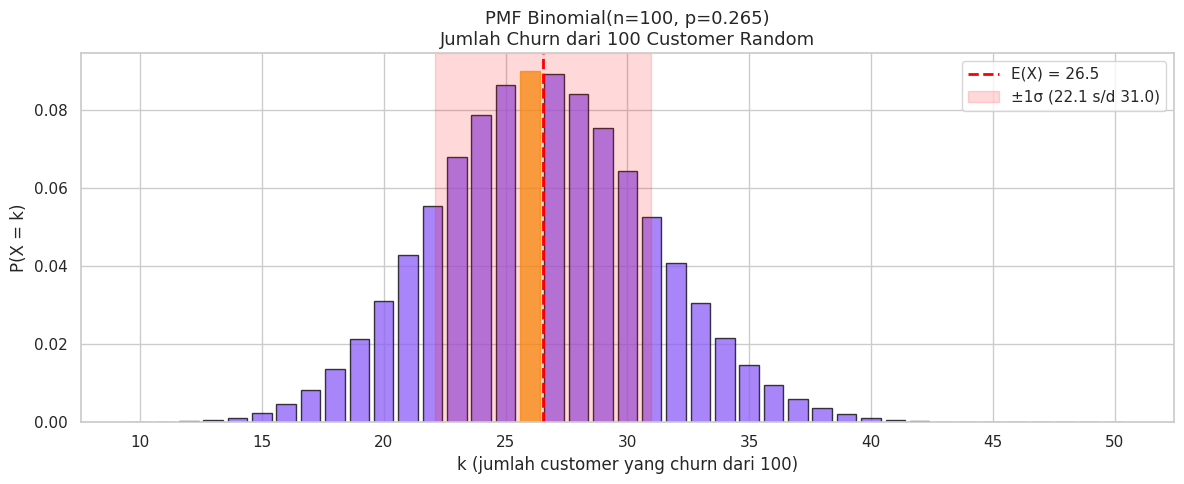

Mode (paling probable): k = 26


In [9]:
# Fokus plot pada daerah yang bermakna (k = 10 s/d 50)
k_plot = np.arange(10, 51)
pmf_plot = binom.pmf(k_plot, n, p)

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(k_plot, pmf_plot, color='#8B5CF6', edgecolor='black', alpha=0.75)

# Highlight E(X) dan range ±1σ
ax.axvline(E_X, color='red', linestyle='--', linewidth=2,
           label=f'E(X) = {E_X:.1f}')
ax.axvspan(E_X - SD_X, E_X + SD_X, alpha=0.15, color='red',
           label=f'±1σ ({E_X-SD_X:.1f} s/d {E_X+SD_X:.1f})')

# Highlight max bar (mode)
mode_idx = np.argmax(pmf_plot)
bars[mode_idx].set_color('#F59E0B')

ax.set_xlabel('k (jumlah customer yang churn dari 100)', fontsize=12)
ax.set_ylabel('P(X = k)', fontsize=12)
ax.set_title(f'PMF Binomial(n={n}, p={p:.3f})\nJumlah Churn dari 100 Customer Random', fontsize=13)
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()

print(f"Mode (paling probable): k = {k_plot[mode_idx]}")


## D.3 Verifikasi: Bootstrap vs Binomial Teoritis

Mari uji apakah distribusi teoritis Binomial memang cocok dengan sampling nyata dari data.


Bootstrap (1000 sampling × 100 customer):
  Mean   = 26.16  (teori Binomial: 26.54)
  Var    = 18.46  (teori Binomial: 19.49)
  σ      = 4.30  (teori Binomial: 4.42)


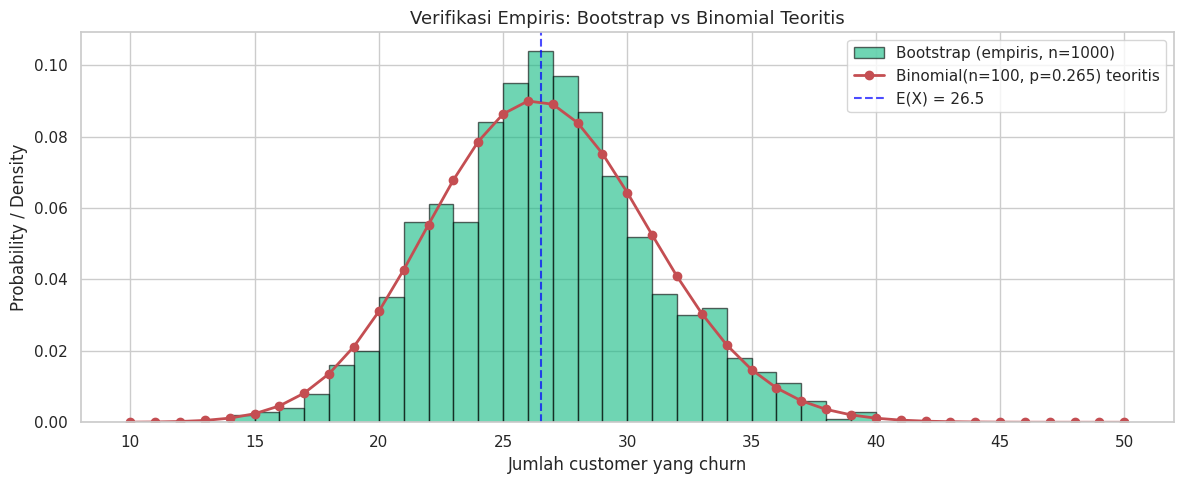

In [10]:
# Bootstrap: ambil random sample 100 customer 1000 kali
np.random.seed(42)
n_simulations = 1000
sample_size = 100

bootstrap_churns = []
for _ in range(n_simulations):
    sample = df.sample(n=sample_size, replace=True)
    n_churned = sample['Churn_binary'].sum()
    bootstrap_churns.append(n_churned)

bootstrap_churns = np.array(bootstrap_churns)

# Statistik empiris dari bootstrap
print(f"Bootstrap (1000 sampling × 100 customer):")
print(f"  Mean   = {bootstrap_churns.mean():.2f}  (teori Binomial: {E_X:.2f})")
print(f"  Var    = {bootstrap_churns.var():.2f}  (teori Binomial: {Var_X:.2f})")
print(f"  σ      = {bootstrap_churns.std():.2f}  (teori Binomial: {SD_X:.2f})")

# Visualisasi comparison
fig, ax = plt.subplots(figsize=(12, 5))

# Empirical from bootstrap
ax.hist(bootstrap_churns, bins=range(10, 51), density=True, alpha=0.6,
        color='#10B981', edgecolor='black', label='Bootstrap (empiris, n=1000)')

# Theoretical Binomial PMF
k_plot = np.arange(10, 51)
pmf_plot = binom.pmf(k_plot, n, p)
ax.plot(k_plot, pmf_plot, 'ro-', linewidth=2, markersize=6,
        label=f'Binomial(n={n}, p={p:.3f}) teoritis')

ax.axvline(E_X, color='blue', linestyle='--', alpha=0.7, label=f'E(X) = {E_X:.1f}')
ax.set_xlabel('Jumlah customer yang churn', fontsize=12)
ax.set_ylabel('Probability / Density', fontsize=12)
ax.set_title('Verifikasi Empiris: Bootstrap vs Binomial Teoritis', fontsize=13)
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()


---

# ⚡ E. Distribusi Poisson: Monthly Churn Rate

**Tujuan Pembelajaran 3** — Model rate kejadian langka dengan Poisson.

## E.1 Setup: Churn per Bulan

Misal kita punya ~2,900 customer di segmen Month-to-month (churn rate ~43%). Rata-rata churn/bulan bisa dimodelkan dengan Poisson.


In [11]:
# Asumsi: dari 2900 customer Month-to-month, rata-rata ~104 churn per bulan
# (asumsi: 42.7% rata annual spread merata 12 bulan)

n_mtm = (df['Contract'] == 'Month-to-month').sum()
churn_rate_mtm = df[df['Contract'] == 'Month-to-month']['Churn_binary'].mean()

# Asumsi: churn rate spread uniformly across tenure months
# Monthly expected churn = total_mtm_churned / avg_tenure
avg_tenure = df[df['Contract'] == 'Month-to-month']['tenure'].mean()
total_churned_mtm = df[df['Contract'] == 'Month-to-month']['Churn_binary'].sum()

# Lambda = rate per bulan
lambda_rate = total_churned_mtm / avg_tenure

print(f"Setup Poisson Model untuk Monthly Churn:")
print(f"  Total MTM customer    = {n_mtm}")
print(f"  Total MTM churned     = {total_churned_mtm}")
print(f"  Average tenure (bln)  = {avg_tenure:.1f}")
print(f"  λ (rate per bulan)    = {lambda_rate:.2f}")

# Verifikasi sifat Poisson: E(X) = Var(X) = λ
print(f"\nSifat Poisson(λ={lambda_rate:.2f}):")
print(f"  E(X)   = λ   = {lambda_rate:.2f}")
print(f"  Var(X) = λ   = {lambda_rate:.2f}")
print(f"  σ            = {np.sqrt(lambda_rate):.2f}")


Setup Poisson Model untuk Monthly Churn:
  Total MTM customer    = 3875
  Total MTM churned     = 1655
  Average tenure (bln)  = 18.0
  λ (rate per bulan)    = 91.76

Sifat Poisson(λ=91.76):
  E(X)   = λ   = 91.76
  Var(X) = λ   = 91.76
  σ            = 9.58


## E.2 PMF Poisson & Pertanyaan Praktis


In [12]:
# PMF untuk k = 0 sampai 100
k_values = np.arange(0, 100)
pmf_values = poisson.pmf(k_values, lambda_rate)

# Pertanyaan praktis
print("Pertanyaan Praktis (Model Poisson Monthly Churn):\n")
print(f"P(X ≤ 40 churn/bulan)   = {poisson.cdf(40, lambda_rate):.4f}")
print(f"P(X ≥ 60 churn/bulan)   = {1 - poisson.cdf(59, lambda_rate):.4f}")
print(f"P(X = 50 exactly)       = {poisson.pmf(50, lambda_rate):.4f}")
print(f"P(45 ≤ X ≤ 55)          = {poisson.cdf(55, lambda_rate) - poisson.cdf(44, lambda_rate):.4f}")

# Deteksi anomali: kalau bulan ini churn 70, apakah ini normal atau alarm?
threshold = 70
p_exceed = 1 - poisson.cdf(threshold - 1, lambda_rate)
print(f"\nAnomaly Detection:")
print(f"  Jika bulan ini churn = {threshold}, P(X ≥ {threshold}) = {p_exceed:.4f}")
if p_exceed < 0.05:
    print(f"  🚨 ANOMALI! Probabilitas < 5% — ada yang tidak biasa.")
else:
    print(f"  ✅ Masih dalam range normal.")


Pertanyaan Praktis (Model Poisson Monthly Churn):

P(X ≤ 40 churn/bulan)   = 0.0000
P(X ≥ 60 churn/bulan)   = 0.9998
P(X = 50 exactly)       = 0.0000
P(45 ≤ X ≤ 55)          = 0.0000

Anomaly Detection:
  Jika bulan ini churn = 70, P(X ≥ 70) = 0.9920
  ✅ Masih dalam range normal.


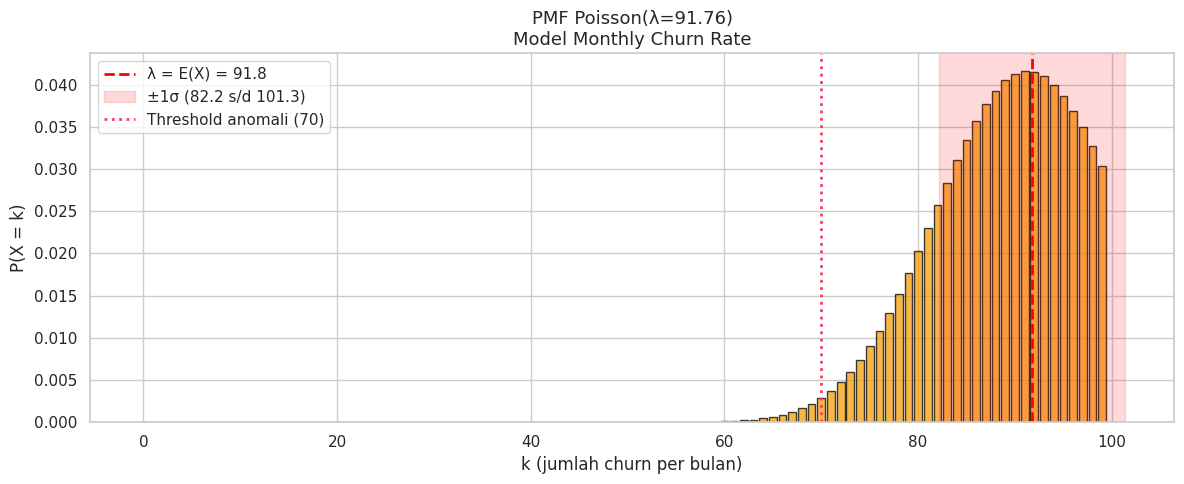

In [13]:
# Visualisasi PMF Poisson
fig, ax = plt.subplots(figsize=(12, 5))

k_plot = np.arange(0, 100)
pmf_plot = poisson.pmf(k_plot, lambda_rate)

ax.bar(k_plot, pmf_plot, color='#F59E0B', edgecolor='black', alpha=0.75)
ax.axvline(lambda_rate, color='red', linestyle='--', linewidth=2,
           label=f'λ = E(X) = {lambda_rate:.1f}')
ax.axvspan(lambda_rate - np.sqrt(lambda_rate), lambda_rate + np.sqrt(lambda_rate),
           alpha=0.15, color='red',
           label=f'±1σ ({lambda_rate-np.sqrt(lambda_rate):.1f} s/d {lambda_rate+np.sqrt(lambda_rate):.1f})')
ax.axvline(70, color='#F43F5E', linestyle=':', linewidth=2,
           label=f'Threshold anomali (70)')

ax.set_xlabel('k (jumlah churn per bulan)', fontsize=12)
ax.set_ylabel('P(X = k)', fontsize=12)
ax.set_title(f'PMF Poisson(λ={lambda_rate:.2f})\nModel Monthly Churn Rate', fontsize=13)
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()


---

# 🧪 F. A/B Testing: Month-to-month vs Two Year — LATIHAN UTAMA

**Tujuan Pembelajaran 4** — Terapkan A/B Testing dengan z-test proporsi.

## F.1 Hipotesis & Setup

**Pertanyaan Bisnis**: Apakah customer dengan Contract Month-to-month punya churn rate BERBEDA SIGNIFIKAN dari Two year? (Jawaban akan menentukan strategi retention perusahaan.)

**Hipotesis**:
- **H₀** (null): p_mtm = p_2year  (tidak ada perbedaan)
- **H₁** (alternative): p_mtm ≠ p_2year  (ada perbedaan signifikan)
- **α** = 0.05 (significance level)


In [14]:
# Grup A: Month-to-month
group_A = df[df['Contract'] == 'Month-to-month']['Churn_binary']
n_A = len(group_A)
x_A = group_A.sum()
p_A = x_A / n_A

# Grup B: Two year
group_B = df[df['Contract'] == 'Two year']['Churn_binary']
n_B = len(group_B)
x_B = group_B.sum()
p_B = x_B / n_B

print(f"Grup A — Month-to-month:")
print(f"  n_A        = {n_A:,} customer")
print(f"  Churn      = {x_A:,}")
print(f"  p̂_A        = {p_A:.4f}  ({p_A*100:.2f}%)")

print(f"\nGrup B — Two year:")
print(f"  n_B        = {n_B:,} customer")
print(f"  Churn      = {x_B:,}")
print(f"  p̂_B        = {p_B:.4f}  ({p_B*100:.2f}%)")

print(f"\nSelisih observasi:")
print(f"  p̂_A − p̂_B  = {p_A - p_B:.4f}  ({(p_A-p_B)*100:.2f} pp)")


Grup A — Month-to-month:
  n_A        = 3,875 customer
  Churn      = 1,655
  p̂_A        = 0.4271  (42.71%)

Grup B — Two year:
  n_B        = 1,695 customer
  Churn      = 48
  p̂_B        = 0.0283  (2.83%)

Selisih observasi:
  p̂_A − p̂_B  = 0.3988  (39.88 pp)


## F.2 Z-Test Proporsi Dua Sampel

Formula uji proporsi dua sampel:

$$z = \frac{\hat{p}_A - \hat{p}_B}{\sqrt{\hat{p}(1-\hat{p})(\frac{1}{n_A} + \frac{1}{n_B})}}$$

dimana $\hat{p} = \frac{x_A + x_B}{n_A + n_B}$ (pooled proportion).


In [15]:
# Pooled proportion
p_pooled = (x_A + x_B) / (n_A + n_B)
print(f"Pooled proportion: p̂ = {p_pooled:.4f}")

# Standard error pooled
SE = np.sqrt(p_pooled * (1 - p_pooled) * (1/n_A + 1/n_B))
print(f"Standard Error    : SE = {SE:.6f}")

# Z-statistic
z_stat_manual = (p_A - p_B) / SE
print(f"Z-statistic manual: z = {z_stat_manual:.4f}")

# P-value (two-tailed)
p_value_manual = 2 * (1 - norm.cdf(abs(z_stat_manual)))
print(f"P-value two-tailed: p = {p_value_manual:.6e}")

# Verifikasi dengan statsmodels
counts = np.array([x_A, x_B])
nobs = np.array([n_A, n_B])
z_stat_sm, p_value_sm = proportions_ztest(counts, nobs, alternative='two-sided')

print(f"\nVerifikasi dengan statsmodels:")
print(f"  z-statistic = {z_stat_sm:.4f}")
print(f"  p-value     = {p_value_sm:.6e}")


Pooled proportion: p̂ = 0.3057
Standard Error    : SE = 0.013417
Z-statistic manual: z = 29.7225
P-value two-tailed: p = 0.000000e+00

Verifikasi dengan statsmodels:
  z-statistic = 29.7225
  p-value     = 3.932491e-194


In [16]:
# Kesimpulan statistik
alpha = 0.05

print("=" * 60)
print("KESIMPULAN A/B TEST")
print("=" * 60)
print(f"H₀: p_mtm = p_2year")
print(f"H₁: p_mtm ≠ p_2year")
print(f"α  = {alpha}")
print()
print(f"z = {z_stat_sm:.4f}")
print(f"p-value = {p_value_sm:.2e}")

if p_value_sm < alpha:
    print(f"\n🎯 Reject H₀ (p-value < {alpha})")
    print("✅ Ada perbedaan churn rate yang SIGNIFIKAN antara")
    print("   Month-to-month dan Two year.")
    print(f"\nMonth-to-month punya churn rate {(p_A-p_B)*100:.1f} pp lebih tinggi!")
    print(f"\nAction: Fokuskan retention effort pada customer Month-to-month!")
else:
    print(f"\n⚠️  Fail to reject H₀ (p-value ≥ {alpha})")
    print("Tidak ada bukti perbedaan signifikan.")


KESIMPULAN A/B TEST
H₀: p_mtm = p_2year
H₁: p_mtm ≠ p_2year
α  = 0.05

z = 29.7225
p-value = 3.93e-194

🎯 Reject H₀ (p-value < 0.05)
✅ Ada perbedaan churn rate yang SIGNIFIKAN antara
   Month-to-month dan Two year.

Month-to-month punya churn rate 39.9 pp lebih tinggi!

Action: Fokuskan retention effort pada customer Month-to-month!


## F.3 Visualisasi Hasil A/B Test


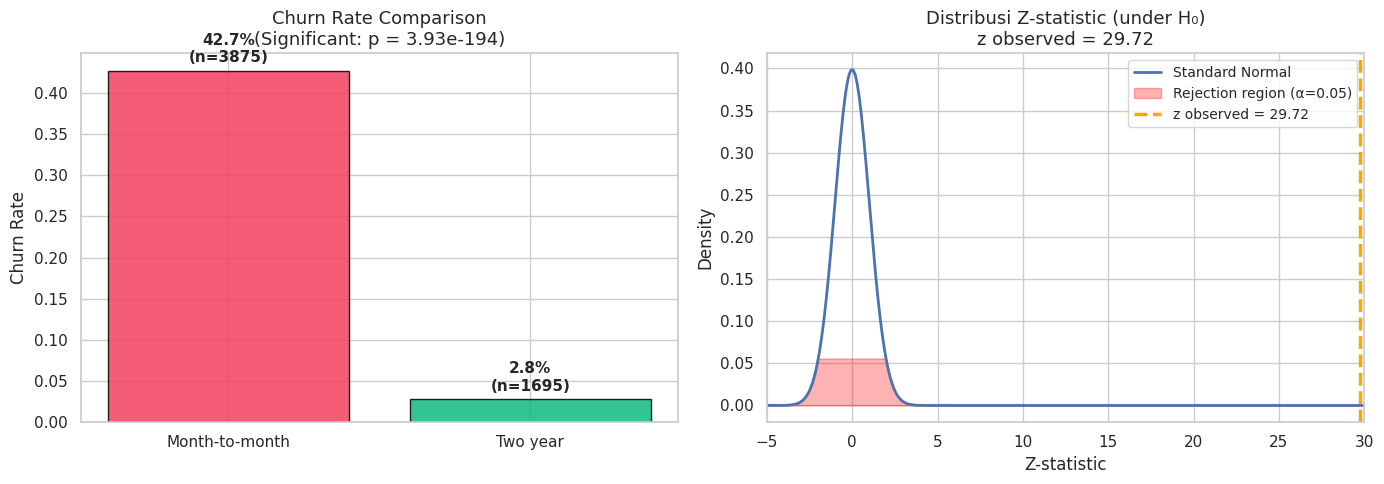


💡 z = 29.72 jauh di luar rejection region ±1.96.
   Ini bukti SANGAT KUAT untuk reject H₀.


In [17]:
# Visualisasi comparison dengan confidence interval
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Bar comparison
groups = ['Month-to-month', 'Two year']
rates = [p_A, p_B]
counts_chart = [n_A, n_B]
colors_grp = ['#F43F5E', '#10B981']

bars = axes[0].bar(groups, rates, color=colors_grp, edgecolor='black', alpha=0.85)
axes[0].set_ylabel('Churn Rate', fontsize=12)
axes[0].set_title(f'Churn Rate Comparison\n(Significant: p = {p_value_sm:.2e})', fontsize=13)

for bar, rate, n in zip(bars, rates, counts_chart):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                 f'{rate*100:.1f}%\n(n={n})',
                 ha='center', fontweight='bold', fontsize=11)

# Right: Sampling distribution under H0
axes[1].set_title(f'Distribusi Z-statistic (under H₀)\nz observed = {z_stat_sm:.2f}', fontsize=13)
z_range = np.linspace(-30, 30, 500)
axes[1].plot(z_range, norm.pdf(z_range), 'b-', linewidth=2, label='Standard Normal')
axes[1].fill_between(z_range[np.abs(z_range) >= 1.96], 0,
                      norm.pdf(z_range[np.abs(z_range) >= 1.96]),
                      alpha=0.3, color='red', label='Rejection region (α=0.05)')
axes[1].axvline(z_stat_sm, color='orange', linestyle='--', linewidth=2.5,
                label=f'z observed = {z_stat_sm:.2f}')
axes[1].set_xlabel('Z-statistic', fontsize=12)
axes[1].set_ylabel('Density', fontsize=12)
axes[1].legend(fontsize=10)
axes[1].set_xlim(-5, 30)

plt.tight_layout()
plt.show()

print(f"\n💡 z = {z_stat_sm:.2f} jauh di luar rejection region ±1.96.")
print(f"   Ini bukti SANGAT KUAT untuk reject H₀.")


---

# 📊 G. A/B Test Multi-Group: PaymentMethod

**Tujuan Pembelajaran 4** — Multi-group comparison + Bonferroni correction.

## G.1 Churn Rate per PaymentMethod


Churn rate per PaymentMethod:
                           n_customers  n_churned  churn_rate
PaymentMethod                                                
Electronic check                  2365       1071      0.4529
Mailed check                      1612        308      0.1911
Bank transfer (automatic)         1544        258      0.1671
Credit card (automatic)           1522        232      0.1524


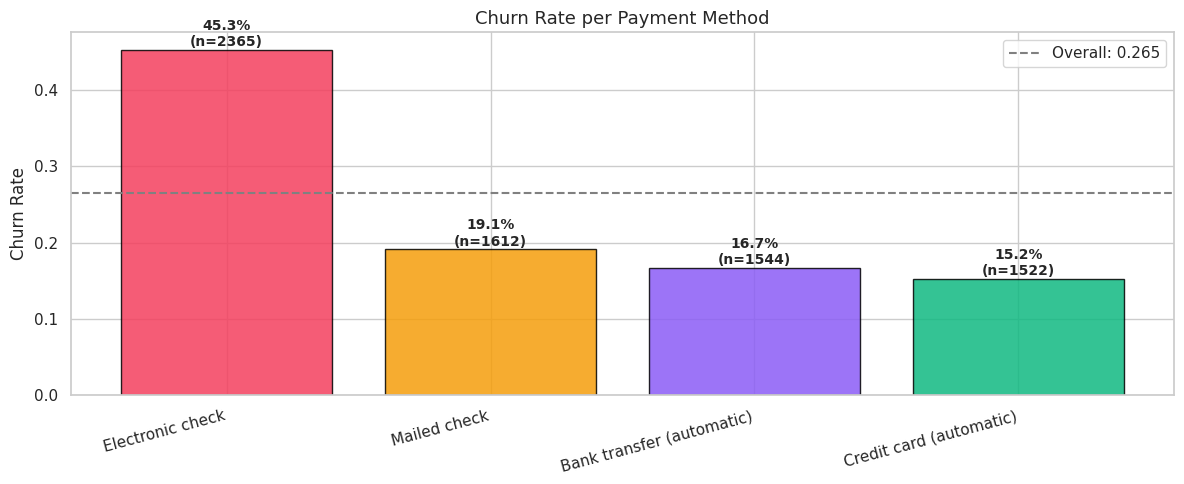

In [18]:
# Analisis per PaymentMethod
payment_summary = df.groupby('PaymentMethod').agg(
    n_customers=('Churn_binary', 'count'),
    n_churned=('Churn_binary', 'sum'),
    churn_rate=('Churn_binary', 'mean')
).round(4).sort_values('churn_rate', ascending=False)

print("Churn rate per PaymentMethod:")
print(payment_summary)

# Visualize
fig, ax = plt.subplots(figsize=(12, 5))
colors_pm = ['#F43F5E', '#F59E0B', '#8B5CF6', '#10B981']
bars = ax.bar(payment_summary.index, payment_summary['churn_rate'].values,
              color=colors_pm, edgecolor='black', alpha=0.85)
ax.set_ylabel('Churn Rate', fontsize=12)
ax.set_title('Churn Rate per Payment Method', fontsize=13)
ax.axhline(overall_churn_rate, color='gray', linestyle='--',
           label=f'Overall: {overall_churn_rate:.3f}')

for bar, rate, n in zip(bars, payment_summary['churn_rate'],
                         payment_summary['n_customers']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{rate*100:.1f}%\n(n={n})',
            ha='center', fontweight='bold', fontsize=10)

ax.legend()
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.show()


## G.2 Pairwise A/B Test dengan Bonferroni Correction

Dengan 4 grup, kita punya C(4,2) = 6 pairwise comparison. Multiple testing problem perlu dikoreksi dengan Bonferroni:

$$\alpha_{\text{adjusted}} = \frac{\alpha}{\text{jumlah test}} = \frac{0.05}{6} = 0.0083$$


In [19]:
from itertools import combinations

payment_methods = df['PaymentMethod'].unique()
pairs = list(combinations(payment_methods, 2))
n_pairs = len(pairs)
alpha_bonferroni = 0.05 / n_pairs

print(f"Total pairwise tests: {n_pairs}")
print(f"Bonferroni-adjusted α: {alpha_bonferroni:.4f}\n")

results = []
for pm_A, pm_B in pairs:
    group_A = df[df['PaymentMethod'] == pm_A]['Churn_binary']
    group_B = df[df['PaymentMethod'] == pm_B]['Churn_binary']

    counts = np.array([group_A.sum(), group_B.sum()])
    nobs = np.array([len(group_A), len(group_B)])

    z_stat, p_value = proportions_ztest(counts, nobs, alternative='two-sided')

    sig = "✅ SIG" if p_value < alpha_bonferroni else "❌ NS"
    results.append({
        'Group A': pm_A,
        'Group B': pm_B,
        'p_A': counts[0] / nobs[0],
        'p_B': counts[1] / nobs[1],
        'z-stat': z_stat,
        'p-value': p_value,
        'Significant (Bonferroni)': sig,
    })

results_df = pd.DataFrame(results).round(4)
print("Hasil Pairwise A/B Tests:")
print(results_df.to_string(index=False))


Total pairwise tests: 6
Bonferroni-adjusted α: 0.0083

Hasil Pairwise A/B Tests:
                  Group A                   Group B    p_A    p_B  z-stat  p-value Significant (Bonferroni)
         Electronic check              Mailed check 0.4529 0.1911 17.0303   0.0000                    ✅ SIG
         Electronic check Bank transfer (automatic) 0.4529 0.1671 18.4372   0.0000                    ✅ SIG
         Electronic check   Credit card (automatic) 0.4529 0.1524 19.3662   0.0000                    ✅ SIG
             Mailed check Bank transfer (automatic) 0.1911 0.1671  1.7545   0.0793                     ❌ NS
             Mailed check   Credit card (automatic) 0.1911 0.1524  2.8625   0.0042                    ✅ SIG
Bank transfer (automatic)   Credit card (automatic) 0.1671 0.1524  1.1082   0.2678                     ❌ NS


> 💡 **Insight bisnis**: Setelah Bonferroni correction, hanya pairs yang **benar-benar signifikan** akan muncul. Hindari false discoveries dengan multiple testing.

> **Action insight**: Customer dengan `Electronic check` punya churn rate sangat tinggi (~45%). Ini jadi target intervensi.


---

# 📝 H. Refleksi & Submit

## H.1 Pertanyaan Refleksi

Jawab 5 pertanyaan di cell markdown di bawah:

1. **Bernoulli**: Jelaskan mengapa setiap customer di dataset bisa dimodelkan sebagai Bernoulli trial. Apa asumsi yang digunakan?

2. **Binomial vs Bernoulli**: Apa hubungan matematis Binomial dengan Bernoulli? Mengapa kita butuh keduanya?

3. **Poisson**: Dalam konteks bisnis telekomunikasi, selain churn/bulan, sebutkan 3 metrik lain yang cocok dimodelkan Poisson. Jelaskan kenapa.

4. **A/B Testing**: Apa yang membuat p-value sangat kecil (seperti 10⁻¹⁵⁰) pada test Contract type? Apakah bukti kuat selalu sama dengan efek besar?

5. **Multiple Testing**: Kenapa kita perlu Bonferroni correction? Apa yang terjadi jika kita abaikan dan melakukan 20 pairwise test tanpa koreksi?

### ✏️ Jawaban Anda:

1. Setiap customer hanya punya dua hasil yang mungkin (churn = 1, tetap = 0) dalam satu percobaan, sehingga cocok disebut Bernoulli trial dengan X ~ Bernoulli(p). Asumsinya ada tiga: (a) hasilnya biner, (b) probabilitas churn p sama untuk semua customer (homogen, di sini p = 0,265), dan (c) customer satu dengan lainnya independen. Asumsi (b) hanya pendekatan, karena churn rate sebenarnya berbeda antar segmen (misalnya Month-to-month 42,7% vs Two year 2,8%).

2. Binomial adalah jumlah dari n Bernoulli yang independen dan identik: X = X₁ + X₂ + … + Xₙ ~ Binomial(n, p). Bernoulli adalah kasus khusus Binomial dengan n = 1. Akibatnya, E(X) = np dan Var(X) = np(1−p) berasal dari penjumlahan n sifat Bernoulli (p dan p(1−p)). Keduanya dibutuhkan karena Bernoulli memodelkan satu individu, sedangkan Binomial memodelkan jumlah kejadian dalam kelompok, dan itu yang dipakai di A/B testing dan perhitungan peluang seperti P(X ≥ 35).

3. Tiga metrik lain yang cocok dimodelkan Poisson:

Jumlah panggilan masuk ke call center per jam.
Jumlah gangguan jaringan atau tower down per minggu.
Jumlah komplain pelanggan per hari.

Ketiganya cocok karena merupakan hitungan kejadian dalam interval waktu tertentu, terjadi secara independen dengan rata-rata (λ) yang relatif konstan, dan tiap kejadian relatif jarang dibanding kemungkinan maksimumnya.

4. P-value sangat kecil karena dua hal bertemu: selisih churn rate besar (±40 poin persentase) dan sampel besar (ribuan customer per grup), sehingga standard error kecil dan z-statistic sangat besar. Bukti kuat tidak selalu berarti efek besar. P-value hanya mengukur seberapa kuat bukti menolak H₀, bukan seberapa besar efeknya. Dengan sampel sangat besar, selisih yang sangat kecil pun bisa memberi p-value kecil. Karena itu laporkan juga effect size dan confidence interval. Pada kasus ini efeknya memang besar (Month-to-month sekitar 15× lebih churn-prone).

5. Setiap uji dengan α = 0,05 punya peluang 5% menghasilkan false positive. Jika uji dilakukan berulang, peluang minimal satu false positive membesar: 1 − (0,95)ᵐ. Untuk 20 uji tanpa koreksi, peluangnya ≈ 1 − 0,95²⁰ ≈ 64%, dan kita secara rata-rata mengharapkan ±1 temuan “signifikan” yang sebenarnya hanya kebetulan. Bonferroni mengendalikan hal ini dengan memakai α_adjusted = α/m (untuk 20 uji = 0,0025). Kekurangannya, metode ini konservatif sehingga power turun dan efek yang nyata bisa terlewat.

## H.2 Checklist Submit

Sebelum submit, pastikan:

- [ ] Semua cell code berhasil dijalankan tanpa error
- [ ] Bernoulli PMF plot muncul dengan benar
- [ ] Binomial PMF memiliki mode yang terlihat
- [ ] Poisson monthly rate λ bisa dihitung
- [ ] A/B test Contract type menghasilkan p-value < 0.05 (reject H₀)
- [ ] Pairwise test PaymentMethod lengkap dengan Bonferroni
- [ ] 5 pertanyaan refleksi sudah dijawab
- [ ] Notebook di-rename: `M5-Praktikum-Distribusi-Diskret-NamaAnda.ipynb`
- [ ] Download dari Colab (File → Download → .ipynb)
- [ ] Upload ke GitHub repository Anda
- [ ] Link GitHub dikumpulkan via LMS Uniska

## H.3 Push ke GitHub

**Melalui Web:**
1. Buka repository `statistika-probabilitas-uniska` di GitHub Anda.
2. Klik folder `notebooks/`, lalu **Add file → Upload files**.
3. Drag & drop file notebook.
4. Commit message: `"Add Modul 5: Distribusi Diskret & A/B Testing"`.
5. Klik **Commit changes**.

---

## 🎓 Selamat! Anda Berhasil...

✅ Memodelkan churn customer sebagai Bernoulli trial  
✅ Menerapkan Binomial untuk n customer dengan bootstrap verification  
✅ Memodelkan monthly churn rate dengan Poisson  
✅ Menjalankan A/B test lengkap dengan Z-test proporsi + Bonferroni correction  

## 📚 Bacaan Lanjutan

- **Bruce, P.** (2020). *Practical Statistics for Data Scientists*, Chapter 2 & 3 (Data & Statistical Experiments).
- **Kohavi, R., Tang, D., & Xu, Y.** (2020). *Trustworthy Online Controlled Experiments: A Practical Guide to A/B Testing*.
- **StatQuest YouTube** — "Binomial Distribution" dan "Hypothesis Testing".

## 🔮 Persiapan Modul 6

Modul 6 mendalami **Distribusi Normal (Gaussian)**:
- N(μ, σ²) dan karakteristik bell curve
- Central Limit Theorem (CLT)
- Z-score & standardisasi
- Normal pada Neural Network weights

**Tugas Mandiri sebelum M6:**
1. Selesaikan Modul-5.ipynb, push ke GitHub
2. Baca Bruce Ch. 2.4-2.6 (Distribusi Diskret)
3. Watch StatQuest "Binomial Distribution" di YouTube
4. **PERSIAPAN QUIZ 2** (bobot 6%) — Bayes + Distribusi Diskret

---

*Notebook by: Prodi Teknik Informatika · Uniska MAB Banjarmasin · Edisi 2026*
